# The zero rows

`cholesterol` and `restingbp` contain zeros that cannot be real measurements.
This notebook looks at who those rows belong to, and whether they went missing at random.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from scipy.stats import levene, ttest_ind

import helpers
from helpers import CAT_COLS, NUM_COLS

helpers.setup()

In [2]:
data = helpers.load_data()

zero_share = (data['cholesterol'] == 0).mean() * 100
print(f'Rows with cholesterol = 0: {zero_share:.2f}%')

Rows with cholesterol = 0: 18.74%


## Who are the zero-cholesterol patients?

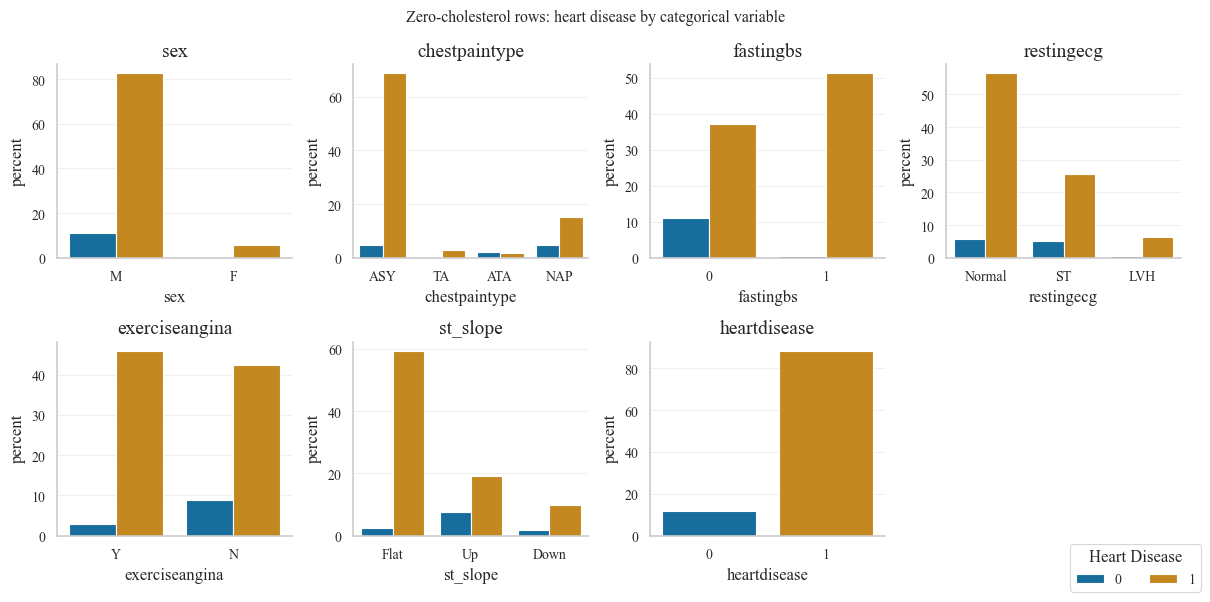

In [3]:
data_zero = data[data['cholesterol'] == 0]

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
axes = axes.flatten()
fig.suptitle('Zero-cholesterol rows: heart disease by categorical variable')

for ax, col in zip(axes, CAT_COLS):
    sns.countplot(data=data_zero, x=col, hue='heartdisease', stat='percent', ax=ax)
    ax.set_title(col)

handles, labels = axes[0].get_legend_handles_labels()
for ax in axes:
    if ax.get_legend():
        ax.get_legend().remove()
fig.legend(handles, labels, title='Heart Disease', loc='upper center',
           ncol=2, bbox_to_anchor=(0.95, 0.1))

axes[-1].set_visible(False)
plt.tight_layout()
plt.show()

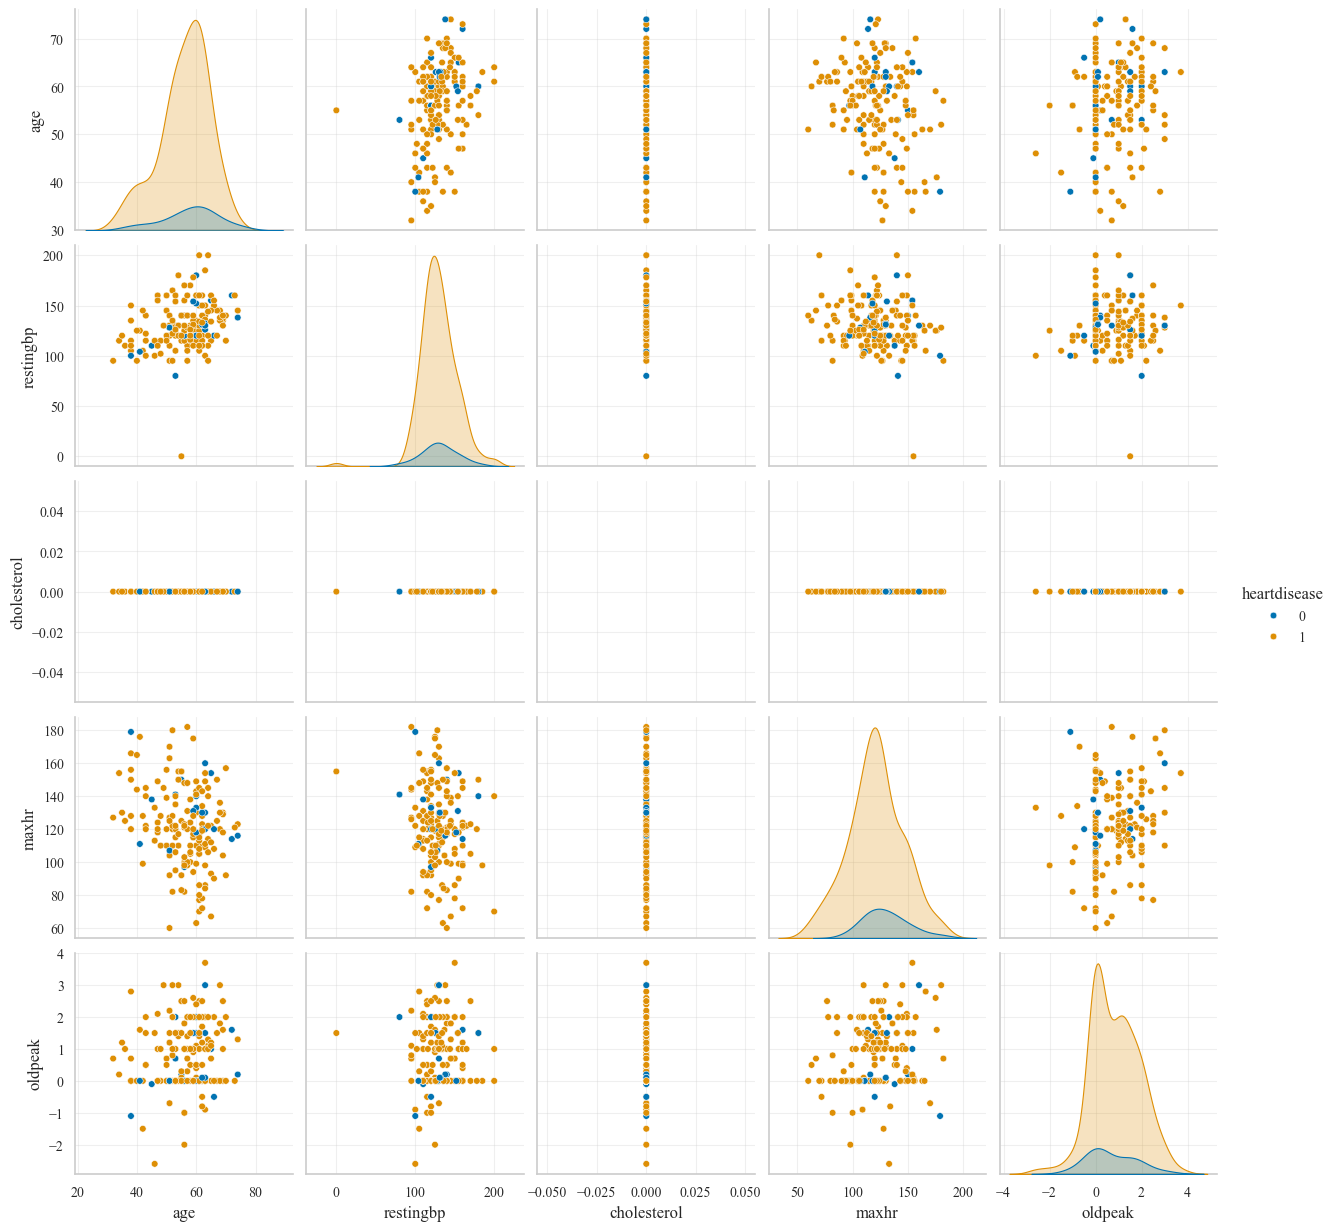

In [4]:
sns.pairplot(data_zero[NUM_COLS + ['heartdisease']], hue='heartdisease')
plt.show()

## Is the missingness random?

Flag every row that has at least one placeholder zero, then compare that group against
the complete rows on the variables that are always observed.

In [5]:
data = helpers.load_data(zeros_as_missing=True)
data['has_missing'] = data.isnull().any(axis=1).astype(int)

complete_cols = [col for col in NUM_COLS if data[col].notna().all()]
print(f'Rows with a missing value: {data["has_missing"].sum()} of {len(data)}')
print(f'Always-observed numerical columns: {complete_cols}')

Rows with a missing value: 172 of 918
Always-observed numerical columns: ['age', 'maxhr', 'oldpeak']


### Levene: do the two groups have the same spread?

H0 is equal variances, so a small p-value means the missing rows are spread differently
from the complete ones.

In [6]:
rows = []
for col in NUM_COLS:
    missing = data.loc[data['has_missing'] == 1, col].dropna()
    complete = data.loc[data['has_missing'] == 0, col].dropna()

    if len(missing) > 10 and len(complete) > 10:
        _, p_value = levene(missing, complete, center='median')
        rows.append({
            'feature': col,
            'var_missing': missing.var(),
            'var_complete': complete.var(),
            'p_value': p_value,
        })

pd.DataFrame(rows).sort_values('p_value')

,feature,var_missing,var_complete,p_value
1,restingbp,431.294737,298.693440,0.008460
0,age,74.241092,90.361905,0.054974
2,maxhr,584.011560,601.431832,0.142657
3,oldpeak,1.080862,1.151031,0.984445


**restingbp**:

- Missingness is associated with heteroscedasticity
- Distribution shape differs, not just location
- Strong evidence against MCAR

**age**:

- Variance difference exists
- p-value: 0.055

 => This is borderline.

Statistically:

- You do not cross the conventional 0.05 threshold
- But the effect is not negligible

Interpretation:

- Weak or marginal evidence
- Consistent with age-related missingness patterns you saw earlier

### Welch's t-test: do the two groups have the same mean?

In [7]:
def missingness_ttest(df, feature_col):
    """Welch's t-test of one feature, missing rows vs complete rows."""
    missing = df.loc[df['has_missing'] == 1, feature_col]
    observed = df.loc[df['has_missing'] == 0, feature_col]

    t_stat, p_value = ttest_ind(missing, observed, nan_policy='omit', equal_var=False)

    return {
        'feature': feature_col,
        'mean_missing': missing.mean(),
        'mean_observed': observed.mean(),
        'mean_diff': missing.mean() - observed.mean(),
        't_statistic': t_stat,
        'p_value': p_value,
        'significant': p_value < 0.05,
    }


results = pd.DataFrame([missingness_ttest(data, col) for col in complete_cols])
results = results.sort_values('p_value')
results

,feature,mean_missing,mean_observed,mean_diff,t_statistic,p_value,significant
1,maxhr,121.988372,140.226542,-18.238169,-8.897594,1.019336e-16,True
0,age,56.238372,52.882038,3.356335,4.514356,9.421125e-06,True
2,oldpeak,0.825581,0.901609,-0.076027,-0.859351,3.909334e-01,False


In [8]:
n_significant = results['significant'].sum()
print(f'Significant at 0.05: {n_significant} of {len(results)} variables tested')

if n_significant:
    print('The missing rows differ from the complete rows, so the data is not MCAR.')
else:
    print('No evidence against MCAR.')

Significant at 0.05: 2 of 3 variables tested
The missing rows differ from the complete rows, so the data is not MCAR.
